# HW1 Part A: SIR model implementation

Implement the SIR model with a hand-written numerical solver (forward Euler or Runge–Kutta). A built-in ODE solver may be used only to verify the implementation.

$$
\begin{aligned}
\frac{dS}{dt} &= -\beta S I \\
\frac{dI}{dt} &= \beta S I - \gamma I \\
\frac{dR}{dt} &= \gamma I
\end{aligned}
$$

- $S$: susceptible, $I$: infected, $R$: recovered
- $\beta$: transmission rate (per person per day)
- $\gamma$: recovery rate (per day)


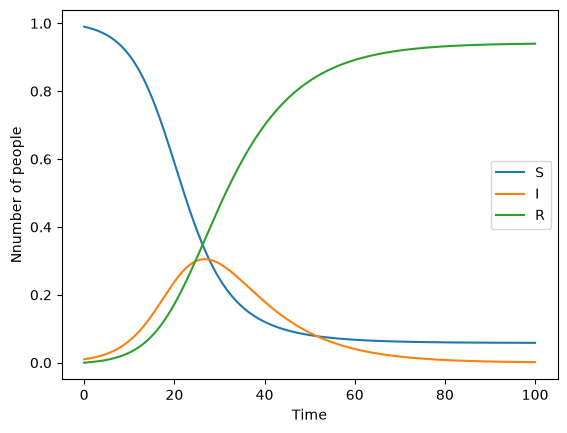

In [1]:
import numpy as np

def forwardEuler(f, y0, t):
    # array of 0's to store inital value and all subsequent solved values
    y = np.zeros((len(t),) + np.shape(y0))
    # add initial condition to beginning of the array
    y[0] = y0
    # iterate over each time step
    for i in range(1, len(t)):
        #compute change in time 
        dt = t[i] - t[i-1]
        #previous time step solution plus time step change
        # multiplied by the derivative at the previous time step
        y[i] = y[i-1] + dt * f(y[i-1], t[i-1])
    return y


def sir_ders(y, beta, gamma):

    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return np.array([dSdt, dIdt, dRdt])

def sir_model(y0, t, beta, gamma):
    def f(y, t):
        return sir_ders(y, beta, gamma)
    return forwardEuler(f, y0, t)


#test the SIR model with initial conditions and parameters
y0 = np.array([0.99, 0.01, 0.0])
t = np.linspace(0, 100, 1000)
beta = 0.3
gamma = 0.1
solution = sir_model(y0, t, beta, gamma)
S, I, R = solution.T

import matplotlib.pyplot as plt
plt.plot(t, S, label='S')
plt.plot(t, I, label='I')
plt.plot(t, R, label='R')
plt.xlabel('Time')
plt.ylabel('Nnumber of people')
plt.legend()
plt.show()